# Final model: a 4.84M-parameter Wide ResNet distilled from two WRN-28-10 teachers

NYU Tandon Deep Learning, Fall 2026, Project 1 (Kaggle: *cifar-10-res-net-architecture-challenge-dl*).

This notebook
1. builds the architecture and prints its parameter count (limit: 5,000,000),
2. loads the trained weights of the submitted model (`k26f`, the selected submission that set our final score),
3. measures its accuracy on the official CIFAR-10 test batch (10,000 labelled images, never trained on),
4. predicts the hidden Kaggle test set and writes `submission.csv`.

Training takes hours, so it runs from the command line (`python train.py --config ...`, see the README); the
training logs of every experiment are plotted in `experiments.ipynb`, and the depth vs width study is in
`depth_width.ipynb`.

In [1]:
import os
import sys
from pathlib import Path

for _var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_var, "1")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display

print(f"torch {torch.__version__}, GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'}")

torch 2.14.1+cu130, GPU: NVIDIA RTX A3000 Laptop GPU


In [2]:
# Chart style: hairline grid and axes, 2px lines, fixed categorical colour order.
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"], "font.size": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-", "axes.axisbelow": True,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "text.color": INK,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2,
    "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
})
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

In [3]:
from resnet5m.data import CLASSES, GpuNormalize, load_cifar10_test, load_test_images
from resnet5m.inference import load_model, predict_probs
from resnet5m.models import PARAM_LIMIT, build_model, count_params

FINAL = "k26f_kd_t4t5_T4_3200ep_full"  # the submitted model: trained on all 50,000 training images
KAGGLE = {"public": 0.907, "private": 0.880}  # hidden-test accuracy from Kaggle; private is the final score
RANK = "15th of 81 teams"  # final (private) leaderboard

## 1. Architecture and parameter count

A pre-activation Wide ResNet (Zagoruyko & Komodakis, 2016) with 28 layers: a 3x3 stem convolution, three
stages of four residual blocks with 64, 128 and 224 channels, then global average pooling and a linear
classifier. Each block computes `y = S(x) + F(x)`, where `F` is BN-ReLU-conv3x3-BN-ReLU-conv3x3 and `S` is
the identity, or a 1x1 convolution where the shape changes (first block of each stage). Stages 2 and 3
halve the resolution with a stride-2 first block.

In [4]:
cfg = yaml.safe_load(open(f"runs/{FINAL}/config.yaml"))
model_cfg = dict(cfg["model"])
model = build_model(model_cfg.pop("name"), **model_cfg)


def n_params(module):
    return sum(p.numel() for p in module.parameters() if p.requires_grad)


n = len(model.blocks) // 3
size = 32
rows = [("stem: 3x3 convolution", 3, model.stem.out_channels, "32x32", n_params(model.stem))]
for i in range(3):
    stage = model.blocks[i * n:(i + 1) * n]
    size //= stage[0].conv1.stride[0]
    rows.append((f"stage {i + 1}: {n} residual blocks", stage[0].conv1.in_channels, stage[-1].conv2.out_channels,
                 f"{size}x{size}", n_params(stage)))
rows.append(("BN-ReLU, global average pool, linear", model.fc.in_features, model.fc.out_features, "1x1",
             n_params(model.bn) + n_params(model.fc)))
layers = pd.DataFrame(rows, columns=["layer", "in channels", "out channels", "output size", "parameters"])
total = count_params(model)
assert total == layers["parameters"].sum()
display(layers.assign(parameters=layers["parameters"].map("{:,}".format)))
print(f"Total trainable parameters: {total:,} (limit {PARAM_LIMIT:,}, {total / PARAM_LIMIT:.1%} of the budget)")
assert total <= PARAM_LIMIT

,layer,in channels,out channels,output size,parameters
0,stem: 3x3 convolution,3,16,32x32,432
1,stage 1: 4 residual blocks,16,64,32x32,"269,216"
2,stage 2: 4 residual blocks,64,128,16x16,"1,116,032"
3,stage 3: 4 residual blocks,128,224,8x8,"3,451,200"
4,"BN-ReLU, global average pool, linear",224,10,1x1,"2,698"


Total trainable parameters: 4,839,578 (limit 5,000,000, 96.8% of the budget)


In [5]:
print(model.blocks[n])  # the first block of stage 2: stride 2 and a 1x1 projection shortcut

PreActBlock(
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (dropout): Identity()
  (se): Identity()
  (bn3): Identity()
  (reg): Identity()
  (shortcut): Conv2d(64, 128, kernel_size=(1, 1), stride=(2, 2), bias=False)
)


## 2. The trained model

Recipe (`configs/kd_wrn28_from_t1.yaml` with the overrides in `queues/hpc10.txt`): SGD with Nesterov momentum
0.9 (batch 128, peak lr 0.1 after a 5-epoch warmup, cosine decay to 0 over 3,200 epochs, weight decay 5e-4
except on BN and biases); random crop + flip, TrivialAugment, Cutout and CutMix/MixUp on every batch; an
exponential moving average of the weights (decay 0.9995) is the final model. The loss is 90% knowledge
distillation (temperature 4) and 10% cross-entropy with the (mixed) labels. The two teachers are WRN-28-10s
with 36.5M parameters each, trained from scratch by us on the same training images; the 5M limit applies to
the submitted model, not to the networks used during training. The teachers label exactly the augmented, mixed
image the student sees ("function matching", Beyer et al., 2022).

In [6]:
ckpt = torch.load(f"runs/{FINAL}/model_final.pt", map_location="cpu", weights_only=False)
s = ckpt["summary"]
kd = cfg["kd"]
print(f"{FINAL}: {count_params(final):,} trainable parameters")
print(f"trained for {s['epochs']:,} epochs ({s['train_hours']:.1f} hours on one A100) on all 50,000 training images")
print(f"loss: {1 - kd['alpha']:.0%} distillation (temperature {kd['temperature']:g}) + {kd['alpha']:.0%} cross-entropy")

teacher_rows = []
for path in kd["teachers"]:
    run = Path(path).parent.name
    t_sum = json.load(open(f"runs/{run}/summary.json"))
    t_cfg = yaml.safe_load(open(f"runs/{run}/config.yaml"))
    teacher_rows.append({"teacher": run, "widths": t_sum["model"]["widths"], "parameters": f"{t_sum['params']:,}",
                         "epochs": t_sum["epochs"], "training images": f"{50_000 - t_cfg['data']['val_size']:,}"})
display(pd.DataFrame(teacher_rows).set_index("teacher"))

k26f_kd_t4t5_T4_3200ep_full: 4,839,578 trainable parameters
trained for 3,200 epochs (9.4 hours on one A100) on all 50,000 training images
loss: 90% distillation (temperature 4) + 10% cross-entropy


,widths,parameters,epochs,training images
teacher,,,,
t4_wrn28_10_800ep_seed1,"[160, 320, 640]","36,479,194",800,"45,000"
t5f_wrn28_10_800ep_seed2_full,"[160, 320, 640]","36,479,194",800,"50,000"


## 3. Accuracy on held-out labelled images: the CIFAR-10 test set

The final model and one of its teachers (`t5f`) trained on all 50,000 labelled training images, so our
5,000-image validation split is not held out for this model. The official CIFAR-10 test batch is: 10,000
labelled images that no model in this project trained on. We also used it to choose between the final
candidates, so this number carries a mild selection bias. Test-time augmentation (TTA) averages the softmax
over views: `flip` adds the mirror image, `flip_shift` also 1-pixel diagonal shifts (6 views). The Kaggle
submission uses `flip_shift`.

In [7]:
images, labels = load_cifar10_test("data")
xt, yt = torch.from_numpy(images).cuda(), torch.from_numpy(labels).cuda()
norm = GpuNormalize("cuda")

test_acc, c10_probs = {}, {}
for tta in ("none", "flip", "flip_shift"):
    p = predict_probs(final, xt, norm, tta)
    c10_probs[tta] = p.cpu().numpy()
    test_acc[f"TTA {tta}"] = (p.argmax(1) == yt).float().mean().item() * 100
display(pd.DataFrame([test_acc], index=[FINAL]).round(2))
acc = test_acc["TTA flip_shift"]
print(f"CIFAR-10 test accuracy of the final model (10,000 images, flip_shift TTA): {acc:.2f}%")

,TTA none,TTA flip,TTA flip_shift
k26f_kd_t4t5_T4_3200ep_full,98.05,98.24,98.22


CIFAR-10 test accuracy of the final model (10,000 images, flip_shift TTA): 98.22%


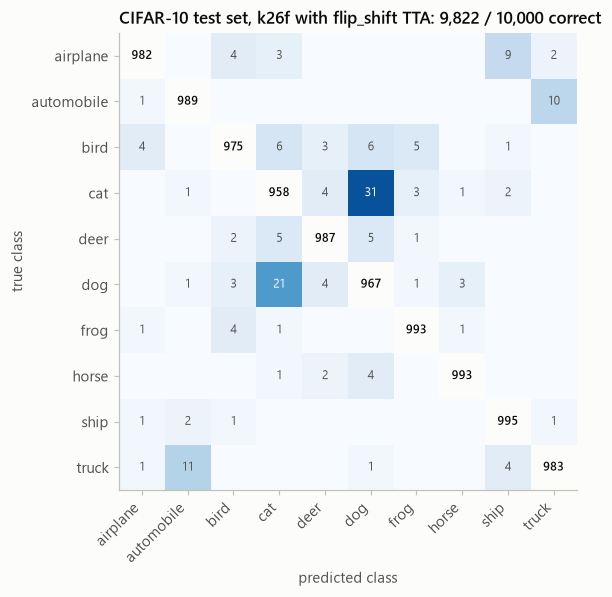

most frequent errors: {'cat -> dog': 31, 'dog -> cat': 21, 'truck -> automobile': 11, 'automobile -> truck': 10, 'airplane -> ship': 9}


In [8]:
pred = c10_probs["flip_shift"].argmax(1)
y = labels
cm = np.zeros((10, 10), int)
np.add.at(cm, (y, pred), 1)

fig, ax = plt.subplots(figsize=(6.2, 5.4))
off = cm.astype(float)
np.fill_diagonal(off, np.nan)  # colour only the errors; the diagonal (correct) is printed in ink
ax.imshow(off, cmap="Blues", vmin=0, vmax=np.nanmax(off) * 1.15)
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            dark = i != j and cm[i, j] > np.nanmax(off) * 0.6
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="#ffffff" if dark else (INK if i == j else INK2), weight="semibold" if i == j else None)
ax.set_xticks(range(10), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(10), CLASSES)
ax.set_xlabel("predicted class")
ax.set_ylabel("true class")
ax.grid(False)
ax.set_title(f"CIFAR-10 test set, {FINAL.split('_')[0]} with flip_shift TTA: "
             f"{np.trace(cm):,} / {cm.sum():,} correct")
fig.savefig(FIG_DIR / "confusion_matrix.png")
plt.show()
errors = pd.Series({f"{CLASSES[i]} -> {CLASSES[j]}": cm[i, j] for i in range(10) for j in range(10) if i != j})
print("most frequent errors:", errors.sort_values(ascending=False).head(5).to_dict())
per_class = pd.Series(np.diag(cm) / cm.sum(1) * 100, index=CLASSES).round(1)
print("per-class accuracy (%):", per_class.to_dict())

## 4. Hidden test set: predictions and submission file

The 2,000 hidden test images (`data/kaggle/test_images`, ids from `test.csv`) are only ever used to write
predictions: no test-time adaptation, no labels.

In [9]:
ids, test_images = load_test_images("data")
test_probs = predict_probs(final, torch.from_numpy(test_images).cuda(), norm, "flip_shift").cpu().numpy()
test_pred = test_probs.argmax(1)
submission = pd.DataFrame({"id": ids, "label": test_pred})
sample = pd.read_csv("data/kaggle/sample_submission.csv")
assert (submission["id"].to_numpy() == sample["id"].to_numpy()).all() and len(submission) == len(sample)
submission.to_csv("submission.csv", index=False)
print(f"wrote submission.csv: {len(submission)} predictions")
submitted = Path(f"submissions/{FINAL}_flipshift.csv")
if submitted.exists():
    same = (pd.read_csv(submitted)["label"].to_numpy() == test_pred).mean()
    print(f"agreement with the file submitted to Kaggle: {same:.2%}")

wrote submission.csv: 2000 predictions
agreement with the file submitted to Kaggle: 99.95%


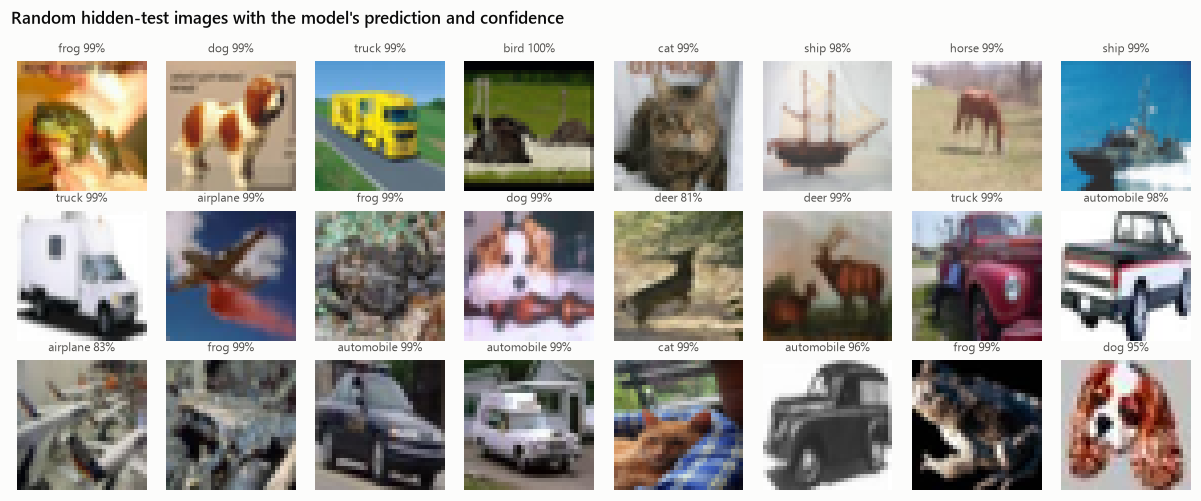

In [10]:
rng = np.random.default_rng(0)
show = rng.choice(len(ids), 24, replace=False)
fig, axes = plt.subplots(3, 8, figsize=(11, 4.6))
for ax, i in zip(axes.flat, show):
    ax.imshow(test_images[i].transpose(1, 2, 0), interpolation="nearest")
    ax.set_title(f"{CLASSES[test_pred[i]]} {test_probs[i].max():.0%}", fontsize=8, loc="center",
                 color=INK2, weight="normal")
    ax.axis("off")
fig.suptitle("Random hidden-test images with the model's prediction and confidence", x=0.01, ha="left",
             fontsize=11, weight="semibold")
fig.tight_layout()
fig.savefig(FIG_DIR / "test_predictions.png")
plt.show()

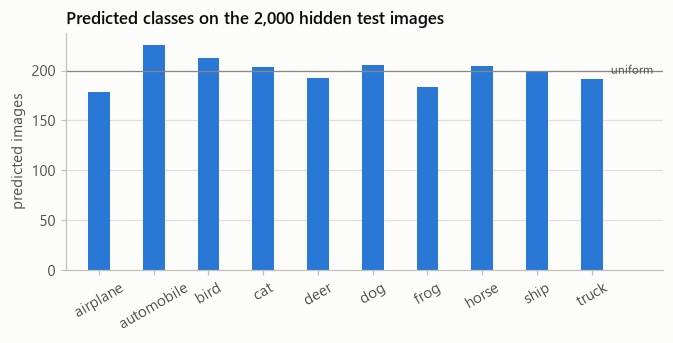

{'airplane': 178, 'automobile': 226, 'bird': 213, 'cat': 204, 'deer': 193, 'dog': 206, 'frog': 183, 'horse': 205, 'ship': 200, 'truck': 192}


In [11]:
counts = np.bincount(test_pred, minlength=10)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(CLASSES, counts, width=0.4, color=BLUE)
ax.axhline(len(test_pred) / 10, color=MUTED, lw=0.8)
ax.set_xlim(-0.6, 10.3)
ax.text(9.35, len(test_pred) / 10, "uniform", va="center", fontsize=8, color=INK2)
ax.set_ylabel("predicted images")
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="x", visible=False)
ax.set_title("Predicted classes on the 2,000 hidden test images")
fig.savefig(FIG_DIR / "test_class_counts.png")
plt.show()
print(dict(zip(CLASSES, counts.tolist())))

## 5. Final numbers

In [12]:
print(f"Model {FINAL}: pre-activation WRN-28, widths {cfg['model']['widths']}, "
      f"{count_params(final):,} trainable parameters (limit {PARAM_LIMIT:,})")
print(f"CIFAR-10 test accuracy (10,000 images, flip_shift TTA): {acc:.2f}%")
print(f"Final test accuracy (Kaggle hidden test set): private {KAGGLE['private']:.1%} (final score, {RANK}), "
      f"public {KAGGLE['public']:.1%}")

Model k26f_kd_t4t5_T4_3200ep_full: pre-activation WRN-28, widths [64, 128, 224], 4,839,578 trainable parameters (limit 5,000,000)
CIFAR-10 test accuracy (10,000 images, flip_shift TTA): 98.22%
Final test accuracy (Kaggle hidden test set): private 88.0% (final score, 15th of 81 teams), public 90.7%
